In [ ]:
#configuration

In [1]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

RAW_DIR = BASE_DIR / "dataset" / "raw"
PROCESSED_DIR = BASE_DIR / "dataset" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", BASE_DIR)
print("Raw dataset:", RAW_DIR)
print("Processed dataset:", PROCESSED_DIR)

assert BASE_DIR.exists(), "Project directory not found!"
print("Dataset directories ready!")


Project: D:\AI_IT_HELPDESK
Raw dataset: D:\AI_IT_HELPDESK\dataset\raw
Processed dataset: D:\AI_IT_HELPDESK\dataset\processed
Dataset directories ready!


In [2]:
import pandas as pd
import numpy as np
import random
import re
from collections import Counter

random.seed(42)
np.random.seed(42)

print("Dataset preparation libraries loaded!")

Dataset preparation libraries loaded!


In [ ]:
# initial IT support dataset

In [3]:
records = [
    # ACCOUNT & PASSWORD
    ("I cannot log into my computer", "Account & Password", "High",
     "Verify the username, account status and login error. Follow the approved password reset process."),
    ("I forgot my Windows password", "Account & Password", "Medium",
     "Use the approved password recovery process and verify user identity."),
    ("My account is locked", "Account & Password", "High",
     "Check account lockout status and follow the authorised account unlock procedure."),
    ("I cannot access my user account", "Account & Password", "High",
     "Check account status, authentication details and access permissions."),
    ("My password is not accepted", "Account & Password", "Medium",
     "Check keyboard layout, account status and password reset requirements."),
    ("I need to reset my password", "Account & Password", "Low",
     "Follow the approved password reset and identity verification procedure."),
    ("Windows says my account is disabled", "Account & Password", "High",
     "Verify account status with the system administrator."),
    ("I cannot authenticate to my account", "Account & Password", "High",
     "Check authentication services and account permissions."),
    ("My login credentials are not working", "Account & Password", "Medium",
     "Verify the username and use the approved credential recovery procedure."),
    ("I am unable to sign in after changing my password", "Account & Password", "High",
     "Check credential synchronisation and account authentication status."),

    # NETWORK & VPN
    ("My internet connection is not working", "Network & VPN", "High",
     "Check network connectivity, IP configuration, gateway and DNS settings."),
    ("I cannot connect to the office VPN", "Network & VPN", "High",
     "Check internet access, VPN configuration and authentication status."),
    ("WiFi is connected but there is no internet", "Network & VPN", "High",
     "Check gateway connectivity, DNS resolution and network availability."),
    ("My computer cannot obtain an IP address", "Network & VPN", "High",
     "Check network adapter and DHCP configuration."),
    ("The network connection keeps disconnecting", "Network & VPN", "Medium",
     "Inspect adapter status, connection stability and network logs."),
    ("I cannot access the company network", "Network & VPN", "High",
     "Verify network connectivity, access permissions and VPN requirements."),
    ("DNS server is not responding", "Network & VPN", "Medium",
     "Check DNS configuration and test name resolution."),
    ("VPN connection keeps failing", "Network & VPN", "High",
     "Review VPN client status, server connectivity and authentication errors."),
    ("Network speed is very slow", "Network & VPN", "Medium",
     "Check connection quality, bandwidth usage and network performance."),
    ("I cannot access internal websites", "Network & VPN", "Medium",
     "Check DNS, VPN connectivity and internal network access."),

    # PRINTER
    ("My printer is showing offline", "Printer", "Medium",
     "Check printer power, network connectivity and printer status."),
    ("The printer is not printing documents", "Printer", "Medium",
     "Check print queue, printer connection and error messages."),
    ("My printer paper is jammed", "Printer", "Medium",
     "Follow the manufacturer-approved paper jam removal instructions."),
    ("Printer driver is not working", "Printer", "Medium",
     "Verify the printer model and installed driver compatibility."),
    ("I cannot find the office printer", "Printer", "Low",
     "Check printer network availability and printer installation settings."),
    ("Documents are stuck in the print queue", "Printer", "Medium",
     "Inspect the print queue and follow the approved queue recovery procedure."),
    ("The printer is printing blank pages", "Printer", "Medium",
     "Check paper, toner or ink levels and print settings."),
    ("Printer connection has failed", "Printer", "Medium",
     "Check USB or network connection and printer status."),
    ("My computer cannot detect the printer", "Printer", "Medium",
     "Verify device connectivity and printer driver installation."),
    ("The printer keeps showing an error", "Printer", "Medium",
     "Record the printer error code and consult the device documentation."),

    # SOFTWARE
    ("My application is not opening", "Software", "Medium",
     "Check application error messages, logs and software compatibility."),
    ("I cannot install new software", "Software", "Medium",
     "Check installation permissions, system requirements and installer logs."),
    ("The application keeps crashing", "Software", "High",
     "Review application logs, updates and compatibility requirements."),
    ("Software installation failed", "Software", "Medium",
     "Inspect the installation error and verify dependencies and permissions."),
    ("My application is freezing", "Software", "Medium",
     "Check application resource usage and relevant error logs."),
    ("I receive an error when opening software", "Software", "Medium",
     "Record the error message and check software configuration."),
    ("The software is not responding", "Software", "Medium",
     "Check application processes and system resource availability."),
    ("I need help updating an application", "Software", "Low",
     "Follow the approved software update procedure."),
    ("The application reports a missing file", "Software", "Medium",
     "Check application installation integrity and required dependencies."),
    ("My software license is not working", "Software", "Medium",
     "Verify the licence status and authorised activation details."),

    # SYSTEM HEALTH
    ("My computer is running very slowly", "System Health", "Medium",
     "Inspect CPU, memory, disk usage and running processes."),
    ("My computer has high CPU usage", "System Health", "Medium",
     "Identify high CPU processes and review system resource usage."),
    ("My RAM usage is very high", "System Health", "Medium",
     "Inspect memory consumption and running applications."),
    ("My disk space is almost full", "System Health", "Medium",
     "Check disk usage and identify unnecessary files before approved cleanup."),
    ("My computer is overheating", "System Health", "High",
     "Check temperature, ventilation and hardware health."),
    ("Windows is taking too long to start", "System Health", "Medium",
     "Inspect startup applications, system logs and disk health."),
    ("My computer keeps freezing", "System Health", "High",
     "Check system logs, memory usage and hardware status."),
    ("My computer restarts unexpectedly", "System Health", "High",
     "Review system event logs and hardware or driver errors."),
    ("The hard drive is showing low space", "System Health", "Medium",
     "Analyse storage usage and identify safe cleanup opportunities."),
    ("My system performance has decreased", "System Health", "Medium",
     "Inspect CPU, memory, storage and system performance indicators.")
]

df = pd.DataFrame(
    records,
    columns=[
        "user_query",
        "category",
        "priority",
        "expected_solution"
    ]
)

df.insert(0, "ticket_id", range(1, len(df) + 1))

print("Initial dataset created!")
print("Total records:", len(df))

display(df.head(10))


Initial dataset created!
Total records: 50


,ticket_id,user_query,category,priority,expected_solution
0,1,I cannot log into my computer,Account & Password,High,"Verify the username, account status and login ..."
1,2,I forgot my Windows password,Account & Password,Medium,Use the approved password recovery process and...
2,3,My account is locked,Account & Password,High,Check account lockout status and follow the au...
3,4,I cannot access my user account,Account & Password,High,"Check account status, authentication details a..."
4,5,My password is not accepted,Account & Password,Medium,"Check keyboard layout, account status and pass..."
5,6,I need to reset my password,Account & Password,Low,Follow the approved password reset and identit...
6,7,Windows says my account is disabled,Account & Password,High,Verify account status with the system administ...
7,8,I cannot authenticate to my account,Account & Password,High,Check authentication services and account perm...
8,9,My login credentials are not working,Account & Password,Medium,Verify the username and use the approved crede...
9,10,I am unable to sign in after changing my password,Account & Password,High,Check credential synchronisation and account a...


In [ ]:
# dataset quality

In [4]:
print("Dataset Information")
print("-" * 40)

print("Total records:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate queries:", df["user_query"].duplicated().sum())

print("\nCategory distribution:")
print(df["category"].value_counts())

print("\nPriority distribution:")
print(df["priority"].value_counts())

assert df["user_query"].notna().all()
assert df["category"].notna().all()
assert df["expected_solution"].notna().all()

print("\nDataset validation completed!")


Dataset Information
----------------------------------------
Total records: 50
Missing values: 0
Duplicate queries: 0

Category distribution:
category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64

Priority distribution:
priority
Medium    31
High      16
Low        3
Name: count, dtype: int64

Dataset validation completed!


In [ ]:
# Save initial dataset

In [5]:
RAW_FILE = RAW_DIR / "it_helpdesk_initial_dataset.csv"

df.to_csv(
    RAW_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset saved successfully!")
print("File:", RAW_FILE)

Dataset saved successfully!
File: D:\AI_IT_HELPDESK\dataset\raw\it_helpdesk_initial_dataset.csv


In [ ]:
# Text preprocessing

In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["cleaned_query"] = df["user_query"].apply(clean_text)

df = df.dropna(
    subset=["user_query", "category", "expected_solution"]
)

df = df.drop_duplicates(
    subset=["cleaned_query"]
).reset_index(drop=True)

df["ticket_id"] = range(1, len(df) + 1)

print("Text preprocessing completed!")
display(df[["user_query", "cleaned_query", "category"]].head(10))

Text preprocessing completed!


,user_query,cleaned_query,category
0,I cannot log into my computer,i cannot log into my computer,Account & Password
1,I forgot my Windows password,i forgot my windows password,Account & Password
2,My account is locked,my account is locked,Account & Password
3,I cannot access my user account,i cannot access my user account,Account & Password
4,My password is not accepted,my password is not accepted,Account & Password
5,I need to reset my password,i need to reset my password,Account & Password
6,Windows says my account is disabled,windows says my account is disabled,Account & Password
7,I cannot authenticate to my account,i cannot authenticate to my account,Account & Password
8,My login credentials are not working,my login credentials are not working,Account & Password
9,I am unable to sign in after changing my password,i am unable to sign in after changing my password,Account & Password


In [ ]:
#Visualise dataset distribution

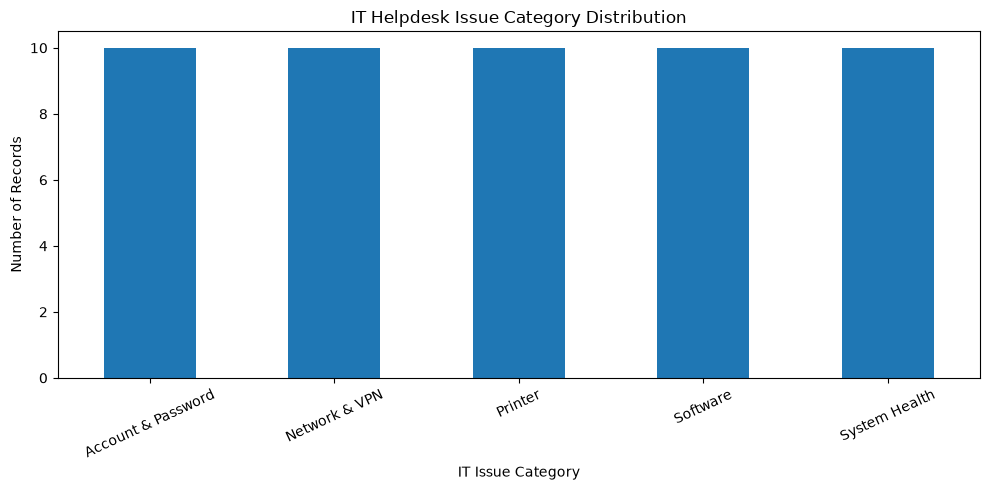

In [7]:

import matplotlib.pyplot as plt

category_counts = df["category"].value_counts()

plt.figure(figsize=(10, 5))

category_counts.plot(
    kind="bar",
    title="IT Helpdesk Issue Category Distribution"
)

plt.xlabel("IT Issue Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

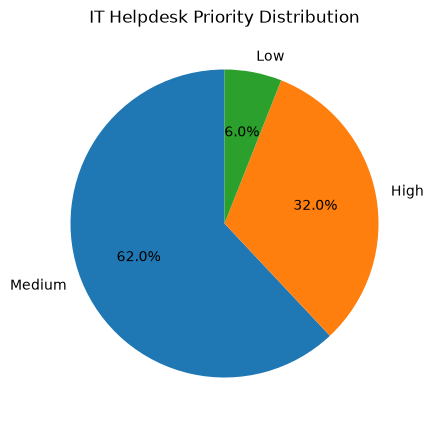

In [8]:
priority_counts = df["priority"].value_counts()

plt.figure(figsize=(7, 5))

priority_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("IT Helpdesk Priority Distribution")
plt.ylabel("")
plt.show()

In [ ]:
# Prepare training, validation and test datasets

In [9]:

from sklearn.model_selection import train_test_split

X = df["cleaned_query"]
y = df["category"]

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))


Training records: 35
Validation records: 7
Testing records: 8


In [ ]:
# Save processed datasets

In [10]:

train_df = pd.DataFrame({
    "user_query": X_train,
    "category": y_train
})

val_df = pd.DataFrame({
    "user_query": X_val,
    "category": y_val
})

test_df = pd.DataFrame({
    "user_query": X_test,
    "category": y_test
})

train_df.to_csv(
    PROCESSED_DIR / "train_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

val_df.to_csv(
    PROCESSED_DIR / "validation_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    PROCESSED_DIR / "test_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

df.to_csv(
    PROCESSED_DIR / "complete_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("All datasets exported successfully!")

All datasets exported successfully!


In [ ]:
# Final dataset verification

In [11]:
print("=" * 50)
print("AI IT HELPDESK - DATASET REPORT")
print("=" * 50)

print("Total Records:", len(df))
print("Categories:", df["category"].nunique())
print("Training Records:", len(train_df))
print("Validation Records:", len(val_df))
print("Testing Records:", len(test_df))

print("\nCategory Summary:")
print(df["category"].value_counts())

print("\nSaved Files:")
for file in PROCESSED_DIR.glob("*.csv"):
    print("[OK]", file.name)

print("\nSTEP 06 DATASET PREPARATION COMPLETED")


AI IT HELPDESK - DATASET REPORT
Total Records: 50
Categories: 5
Training Records: 35
Validation Records: 7
Testing Records: 8

Category Summary:
category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64

Saved Files:
[OK] complete_dataset.csv
[OK] test_dataset.csv
[OK] train_dataset.csv
[OK] validation_dataset.csv

STEP 06 DATASET PREPARATION COMPLETED
